# Weber 3D: campos cuadráticos, soluciones lineales nativas y derivadas

**$a=-1,0,1$; dominio de los ejes $[-25,25]$; cuatro paridades por figura.**
Se conserva la versión recortada de este notebook. Se sustituyen la comparación por
reparametrización y su superposición por las soluciones lineales **en sus variables nativas**.
Las secciones eliminadas por el usuario no se restauran.

La altura es el campo o su derivada, no la coordenada de propagación. Los paneles lineales
usan $t,s\geq0$; la parte negativa de ambos ejes se deja vacía. Las cuatro denominaciones
de paridad identifican las ramas Frobenius heredadas, no una paridad bajo $t\mapsto-t$.
El archivo `weber_core.py`, junto a este notebook, contiene las funciones completas comunes
a este notebook y `Wavefunctions.ipynb`.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
import mpmath as mp
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, Markdown, HTML, Video
import weber_core as wc

A_VALUES=(-1.,0.,1.)
SPAN=25.
N=151
EXPORTAR=True
MOSTRAR_INTERACTIVO=True
OUT=Path.cwd()/'Weber_3D_resultados'
OUT.mkdir(exist_ok=True)
PARITIES=wc.PARITIES
plt.rcParams.update({'font.size':10,'figure.dpi':110,'savefig.dpi':220})
print('Dominio de los ejes: [-25,25]. Lineales: negativos vacíos. Vídeos: 4K/60 fps.')

Dominio de los ejes: [-25,25]. Lineales: negativos vacíos. Vídeos: 4K/60 fps.


## 1. Campos cuadráticos físicos

$$P''+(w^2/4-a)P=0,\quad (P_e(0),P'_e(0))=(1,0),\quad
(P_o(0),P'_o(0))=(0,1).$$
$$\psi_{pq}(x,y;a)=P_p(\sqrt{2k_t}\xi;a)P_q(\sqrt{2k_t}\eta;-a),\quad
x=(\xi^2-\eta^2)/2,\ y=\xi\eta.$$
Se conserva la rama $\xi\geq0$ y $\eta$ con signo del repositorio, y $k_t=0.5$.
Las superficies se separan por semiplano para no unir artificialmente el salto del corte.

In [2]:
# Funciones completas, sin llamadas a definiciones eliminadas.
P=wc.P
field_quadratic=wc.field_quadratic
linear_factor=wc.linear_factor
field_linear=wc.field_linear
atlas=lambda system,a,quantity='field': wc.save_atlas(
    system,a,quantity,OUT,n=N,span=SPAN,dpi=220,show=True)

## 2. Soluciones lineales directas, sin reparametrización

Los ejes de estas figuras son las variables nativas $t,s$, **no** el plano cartesiano $x,y$.
Se resuelve directamente
$$tL''+\tfrac12L'+(t-a)L=0,\qquad t\geq0.$$
Para cada factor $L=t^\alpha G$, con $\alpha=0$ o $1/2$, integramos
$$tG''+(2\alpha+\tfrac12)G'+(t-a)G=0.$$
La inicialización usa la serie regular de Frobenius, con
$$c_{n+1}=\frac{a c_n-c_{n-1}}{(n+1)(n+2\alpha+1/2)}.$$
La normalización es $c_0=1$ para la rama par y $c_0=2$ para la rama impar.
La implementación `linear_basis` **no llama a P ni transforma los ejes mediante raíces**.

Las soluciones de referencia son
$$L_e(t;a)=e^{it}{}_1F_1(1/4+ia/2;1/2;-2it),$$
$$L_o(t;a)=2\sqrt t\,e^{it}{}_1F_1(3/4+ia/2;3/2;-2it).$$
Graficamos $\Phi_{pq}(t,s;a)=L_p(t;a)L_q(s;-a)$ directamente. Por decisión del usuario,
se mantienen los ejes de $-25$ a $25$ y no se evalúa el campo en la región negativa.
Las superficies se ven distintas porque se están usando **planos de variables distintos**;
esto no establece nuevas familias físicas de Helmholtz.

Referencia de las fórmulas de Kummer y sus derivadas:
[NIST DLMF §13.2](https://dlmf.nist.gov/13.2),
[§13.3](https://dlmf.nist.gov/13.3).

In [3]:
# Contrastes independientes de valores y derivadas frente a Kummer a 40 dígitos.
errors={'linear_value':0.,'linear_derivative':0.,'quadratic_value':0.,
        'quadratic_derivative':0.,'cartesian_gradient':0.}
with mp.workdps(40):
    for a in A_VALUES:
        for parity in ('even','odd'):
            b,c=(mp.mpf('.25'),mp.mpf('.5')) if parity=='even' else (mp.mpf('.75'),mp.mpf('1.5'))
            def ref_linear(t):
                return (1 if parity=='even' else 2*mp.sqrt(t))*mp.exp(1j*t)*mp.hyp1f1(b+.5j*a,c,-2j*t)
            def ref_quad(w):
                return (1 if parity=='even' else w)*mp.exp(1j*w*w/4)*mp.hyp1f1(b+.5j*a,c,-.5j*w*w)
            for t0 in (1e-6,.01,.5,3.,12.,25.):
                t=mp.mpf(t0)
                for derivative,key in ((False,'linear_value'),(True,'linear_derivative')):
                    ref=mp.diff(ref_linear,t) if derivative else ref_linear(t)
                    value=wc.linear_factor(t0,a,parity,derivative)
                    errors[key]=max(errors[key],abs(float(value)-float(mp.re(ref)))/(1+abs(float(mp.re(ref)))))
            for w0 in (-11.,-3.,0.,2.,8.,11.):
                w=mp.mpf(w0)
                for derivative,key in ((False,'quadratic_value'),(True,'quadratic_derivative')):
                    ref=mp.diff(ref_quad,w) if derivative else ref_quad(w)
                    errors[key]=max(errors[key],abs(float(wc.P(w0,a,parity,derivative))-float(mp.re(ref)))/(1+abs(float(mp.re(ref)))))
for a in A_VALUES:
    for p,q,_ in PARITIES:
        x=np.array([-3.2,-1.4,.7,2.8]);y=np.array([1.1,-2.3,1.7,-.8]);h=2e-5
        for dim,quantity in ((0,'d1'),(1,'d2')):
            dx,dy=(h,0) if dim==0 else (0,h)
            finite=(wc.field_quadratic(x+dx,y+dy,a,p,q)-wc.field_quadratic(x-dx,y-dy,a,p,q))/(2*h)
            exact=wc.field_quadratic(x,y,a,p,q,quantity=quantity)
            errors['cartesian_gradient']=max(errors['cartesian_gradient'],float(np.max(abs(finite-exact)/(1+abs(exact)))))
assert max(errors.values())<1e-7,errors
assert np.isnan(wc.linear_factor(-1.,0.))
assert np.isnan(wc.linear_factor(0.,0.,'odd',True))
assert np.isnan(wc.field_quadratic(-1.,0.,0.,'odd','even',quantity='d2'))
print(json.dumps(errors,indent=2))
(OUT/'verificacion.json').write_text(json.dumps(errors,indent=2))

{
  "linear_value": 3.3798849884301776e-14,
  "linear_derivative": 5.3118148044926914e-14,
  "quadratic_value": 4.035987355119023e-12,
  "quadratic_derivative": 5.436752872996246e-12,
  "cartesian_gradient": 2.5168042364295446e-11
}


232

## 3. Cuatro paridades en 3D: cuadráticas

Cada panel usa su máximo muestreado $C$; la escala se imprime en su título.
Esta normalización visual no es una normalización de energía. Los ejes manuales compactan
la cuadrícula y mantienen el dominio $[-25,25]^2$ sin deformar el plano de coordenadas.

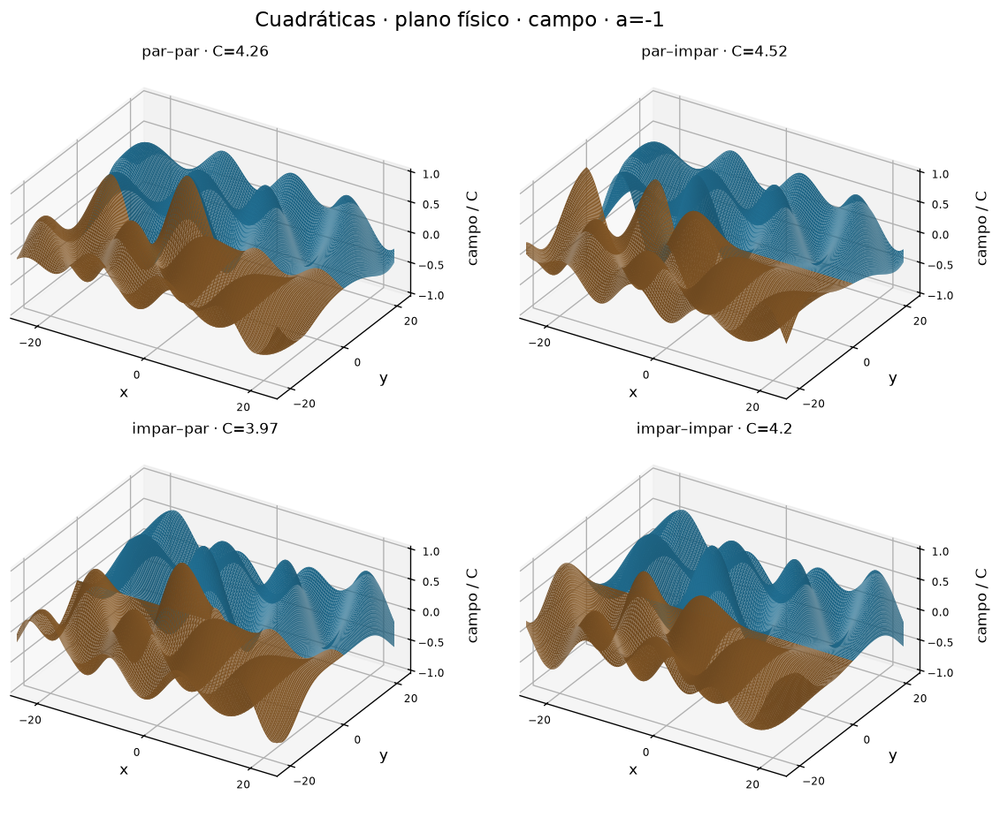

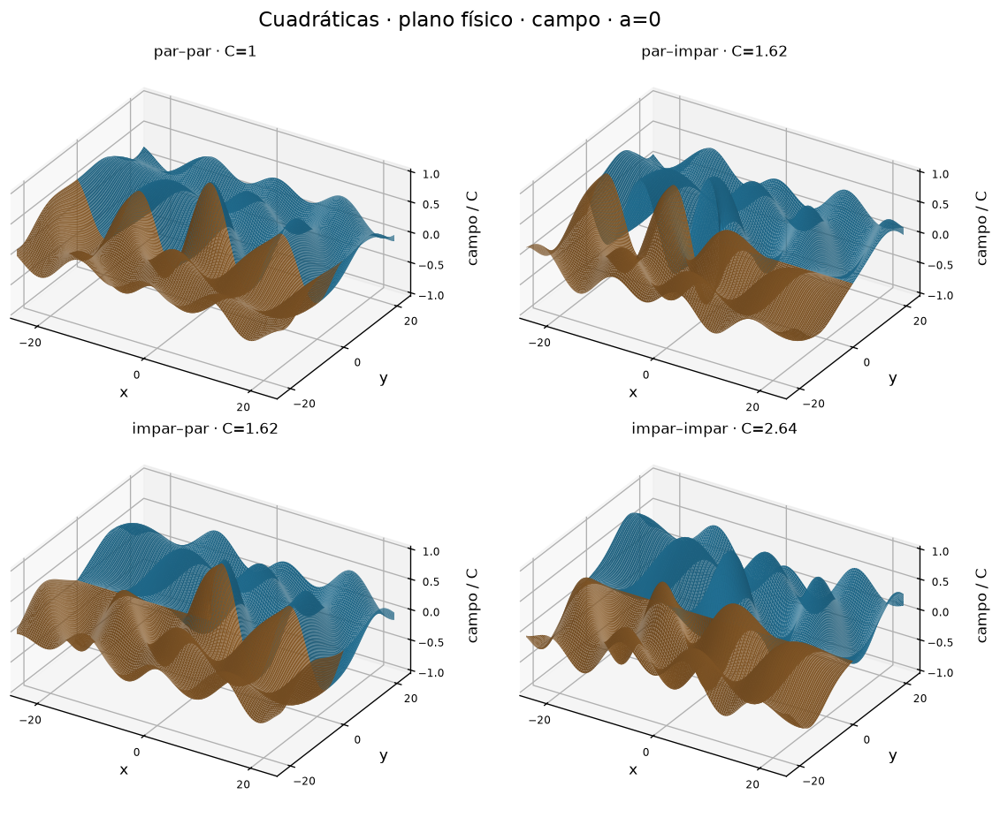

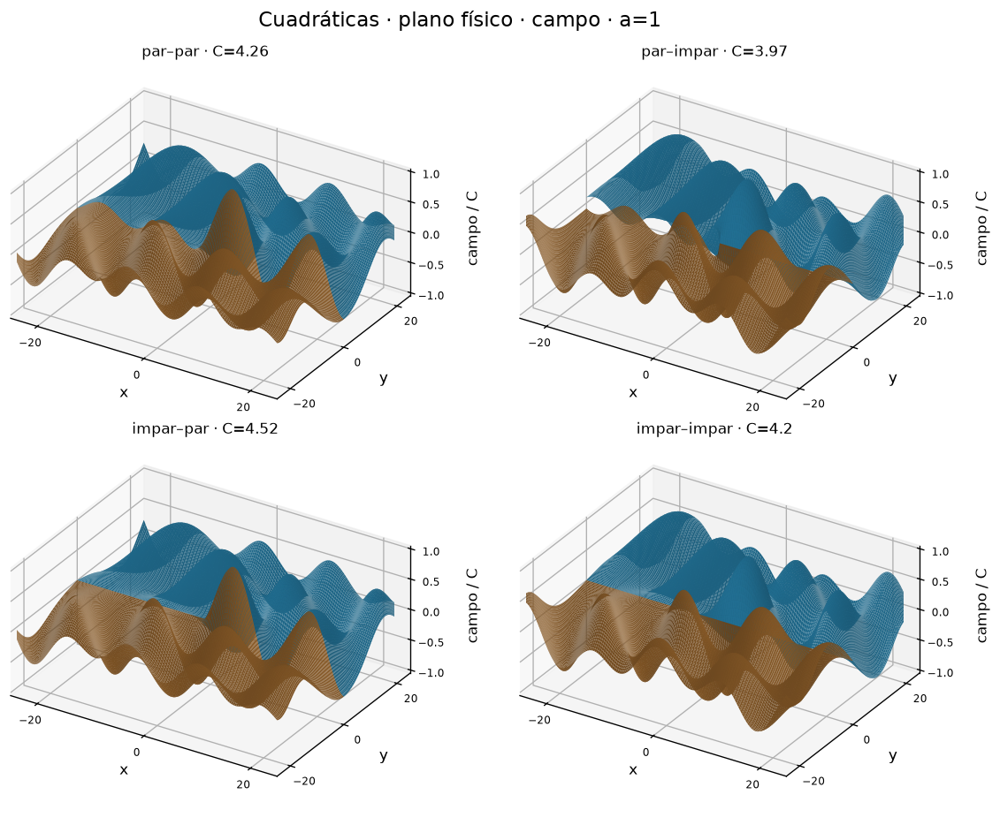

In [4]:
for a in A_VALUES:
    atlas('quadratic',a)

## 4. Cuatro soluciones lineales nativas en 3D

Campo directo $\Phi(t,s)$ sobre el cuadrante $t,s\geq0$. No se aplican `inverse_quadratic`,
`inverse_linear`, un mapa cartesiano ni una reparametrización de las funciones cuadráticas.
La parte negativa de los ejes queda deliberadamente vacía.

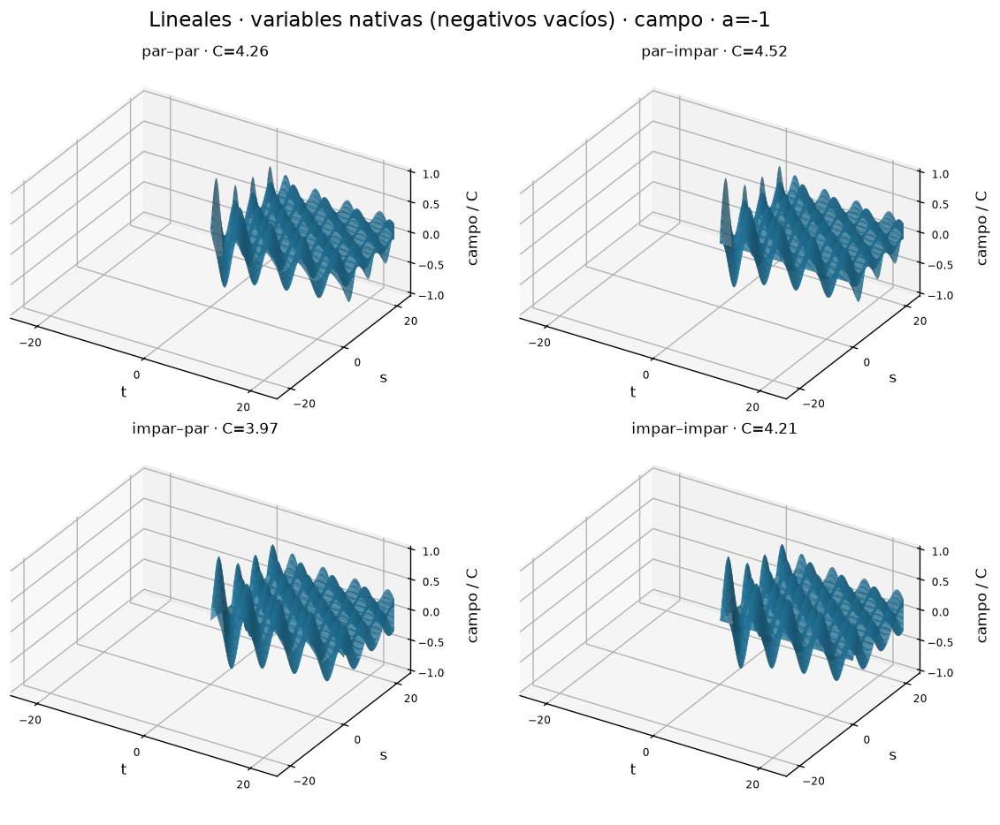

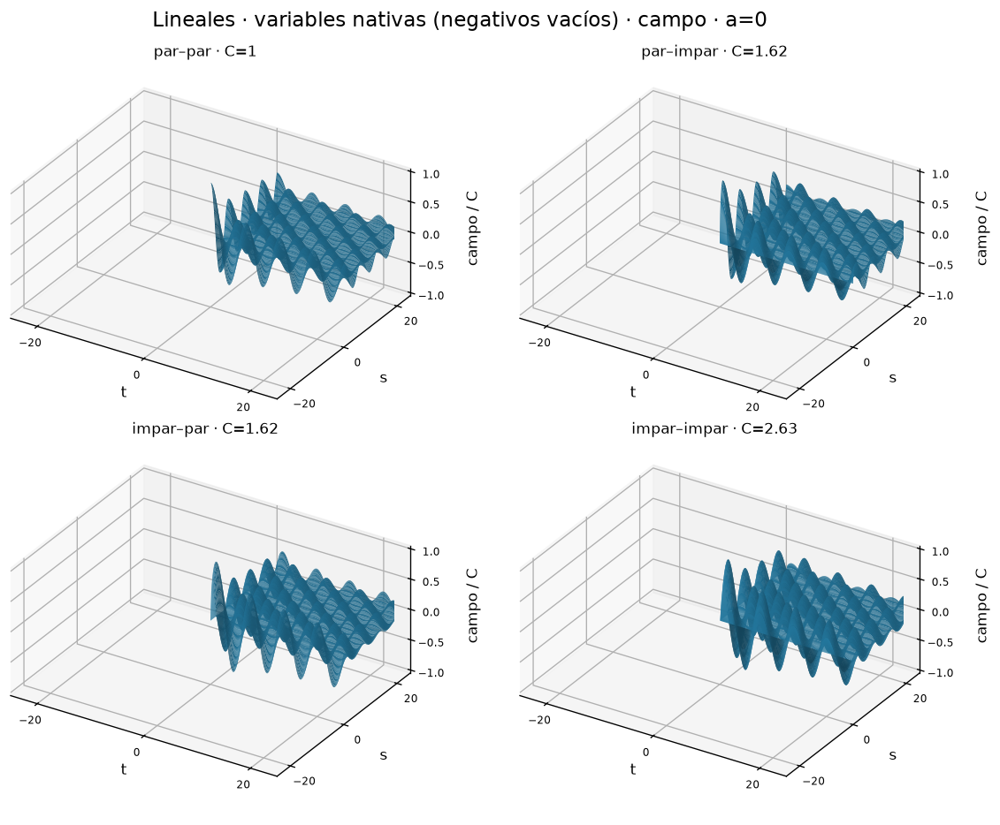

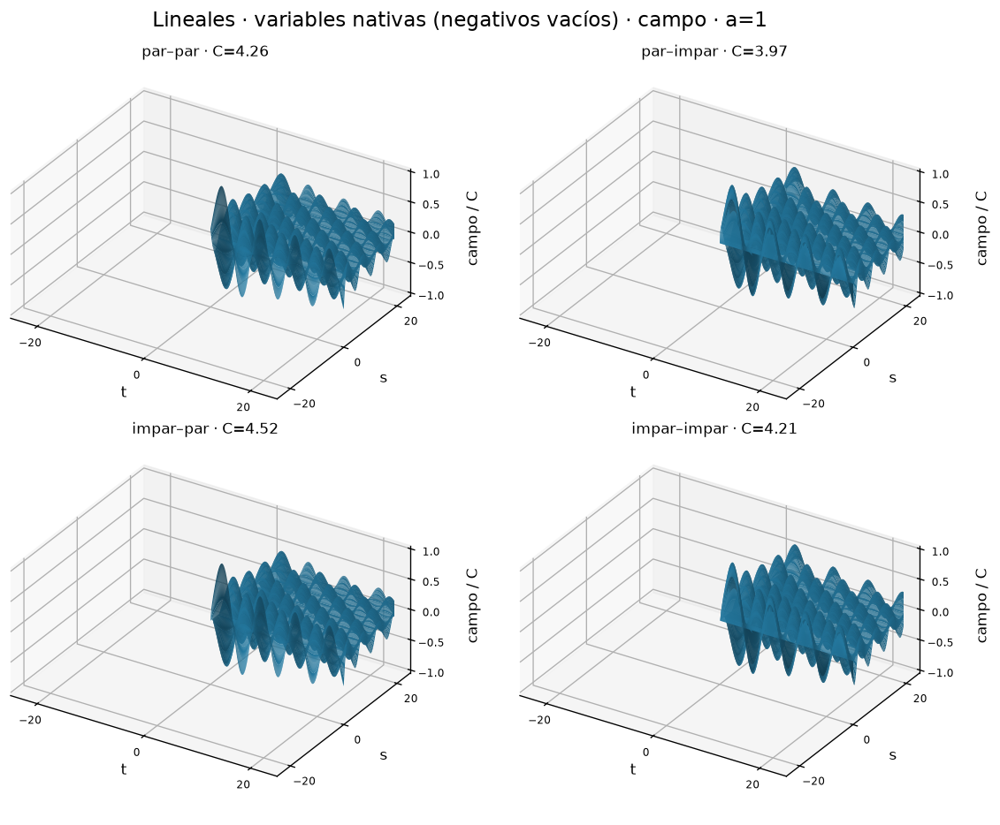

In [5]:
for a in A_VALUES:
    atlas('linear',a)

## 5. Derivadas de las soluciones

Para cuadráticas se grafican las derivadas físicas $\partial_x\psi$ y $\partial_y\psi$
mediante el Jacobiano inverso del mapa parabólico y las derivadas de la EDO.
Para lineales se grafican las derivadas nativas $\partial_t\Phi$ y $\partial_s\Phi$,
evaluando $L'=\alpha t^{\alpha-1}G+t^\alpha G'$ directamente.

No se calculan diferencias finitas a través de un corte. Los puntos donde una derivada
clásica no existe se dejan vacíos. En particular $L'_o(t)\sim1/\sqrt t$ al acercarse
a $0^+$: no se sustituye esa divergencia por cero. Una divergencia de derivada en una
coordenada singular no equivale por sí sola a un salto físico del campo.

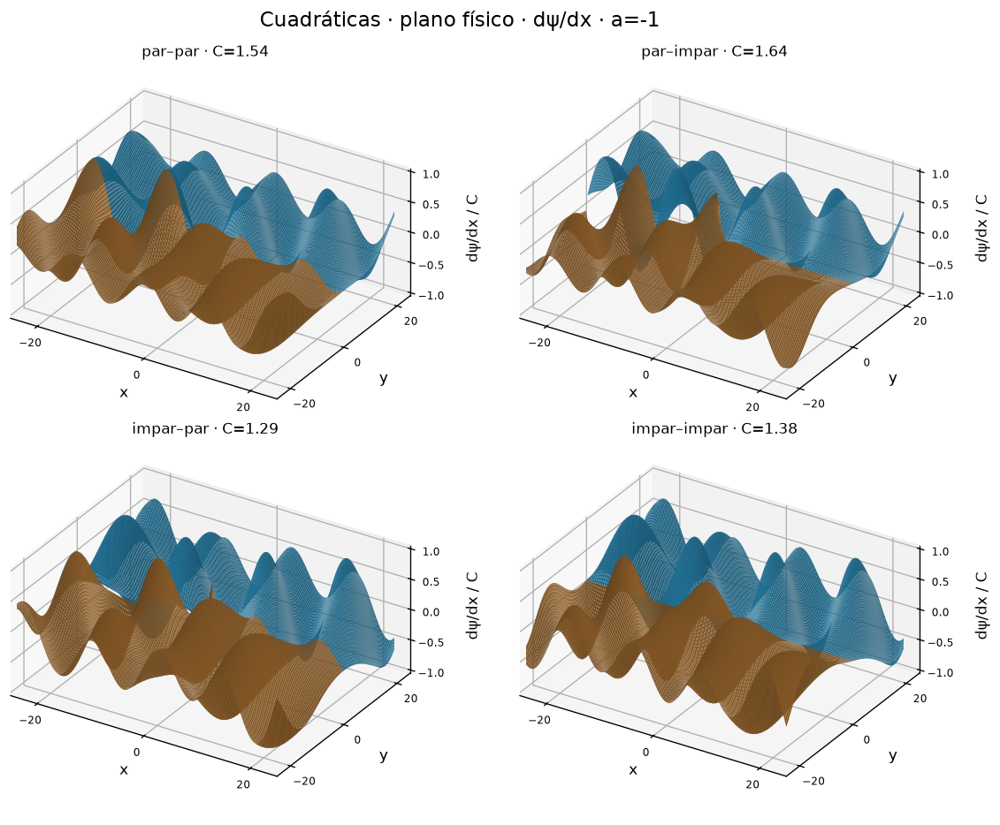

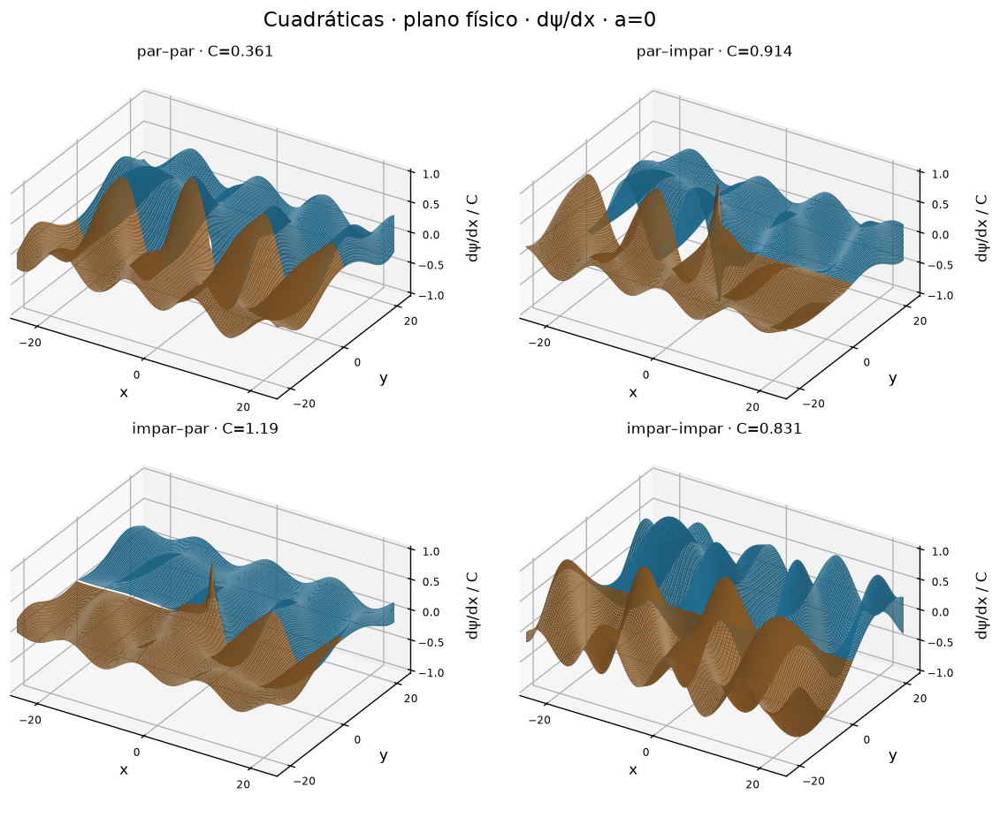

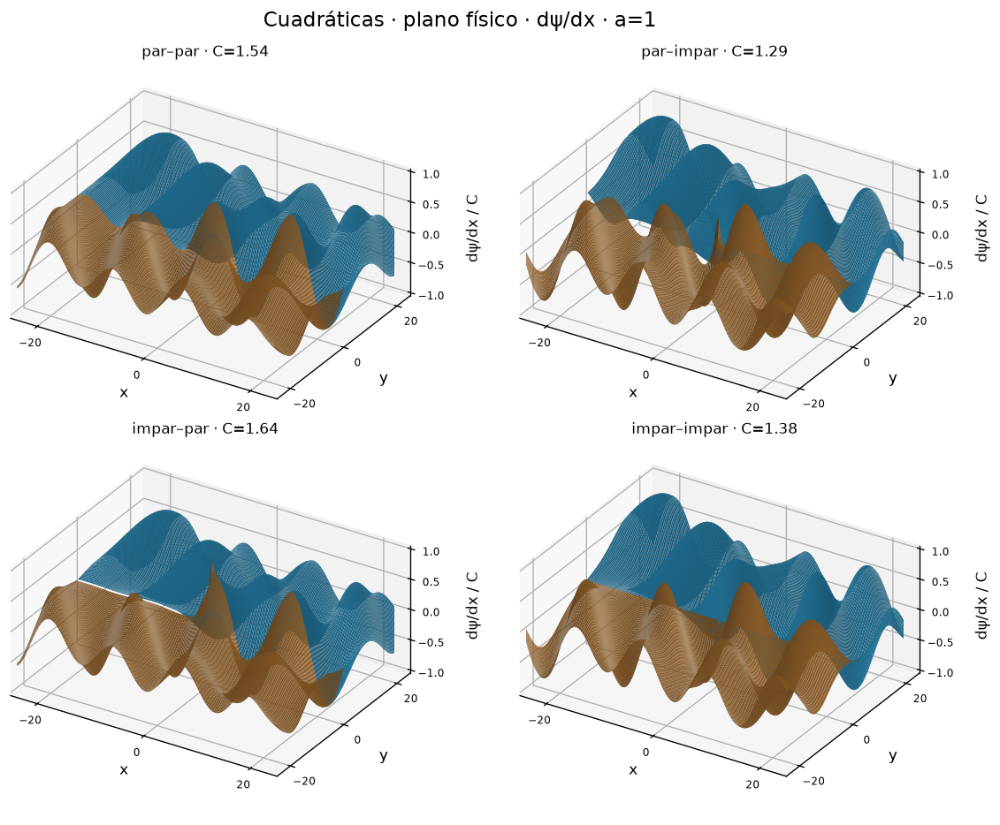

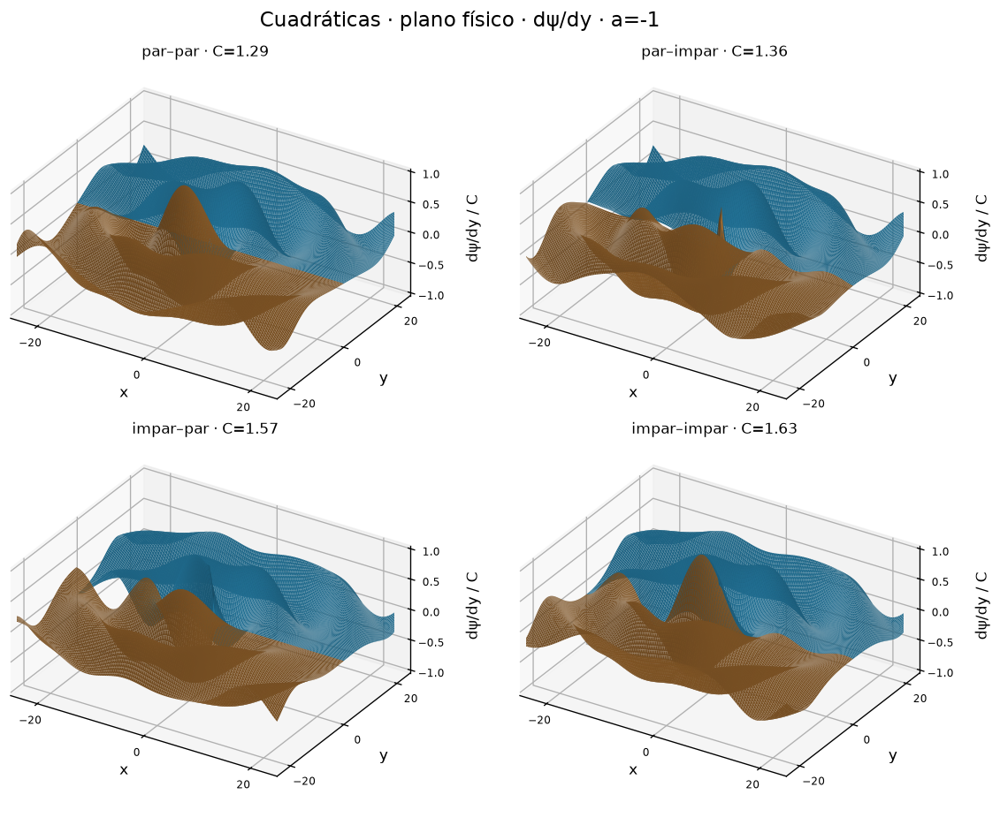

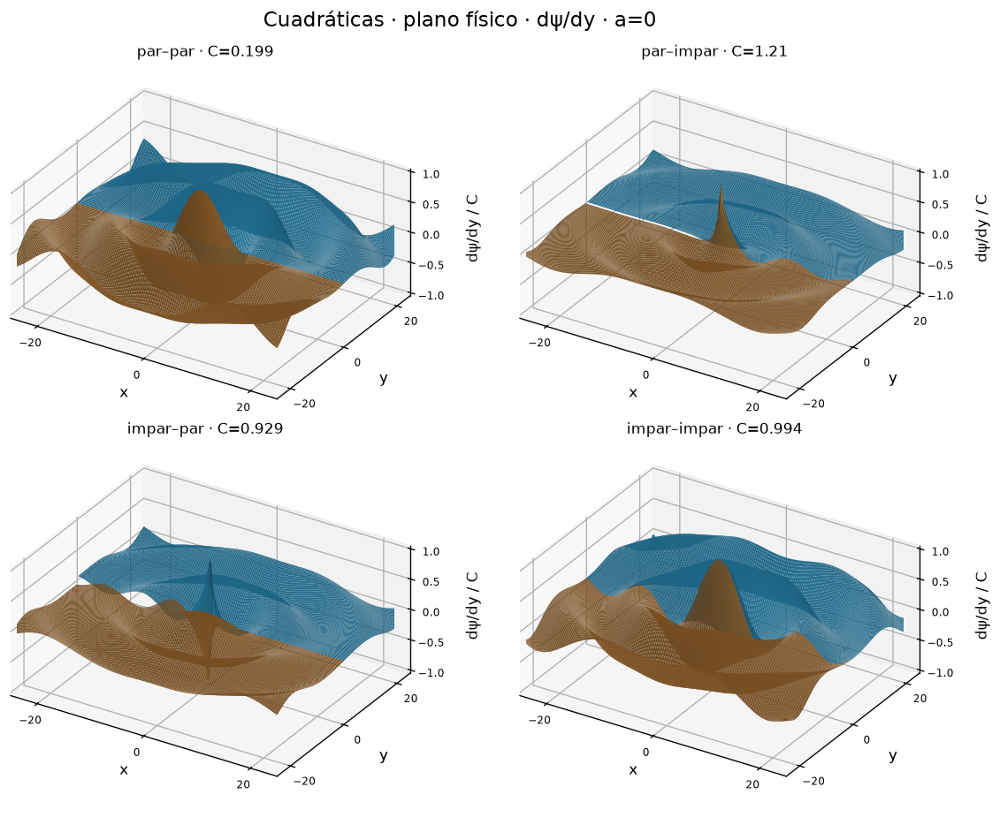

...

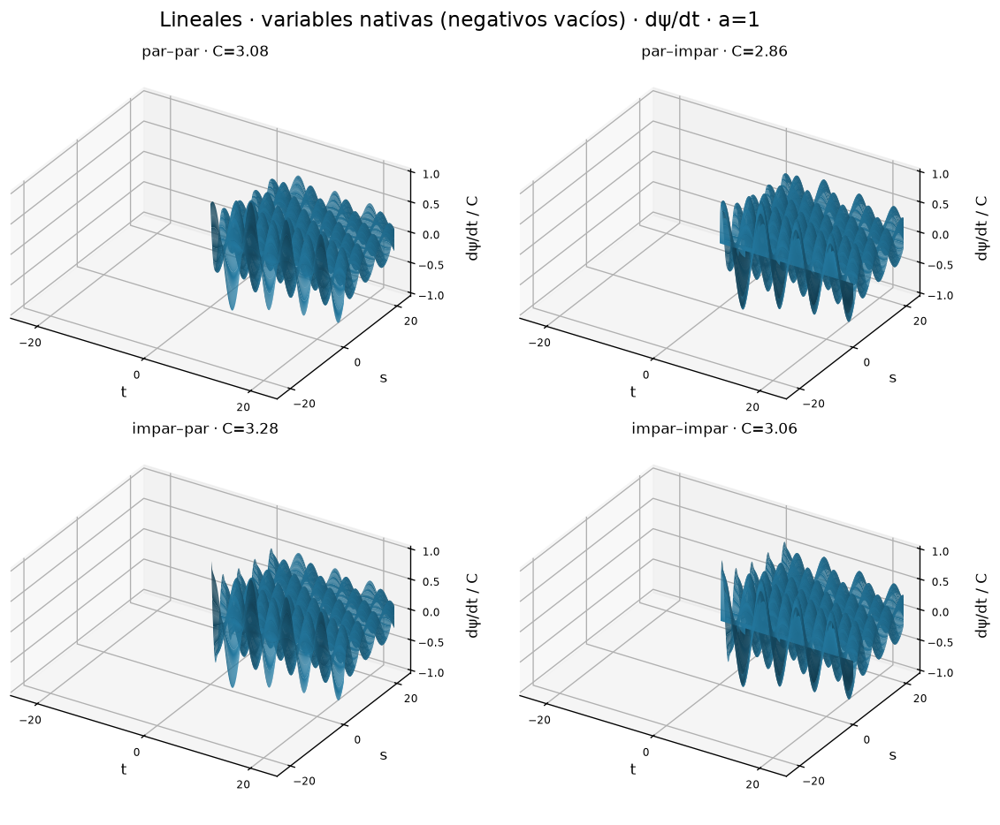

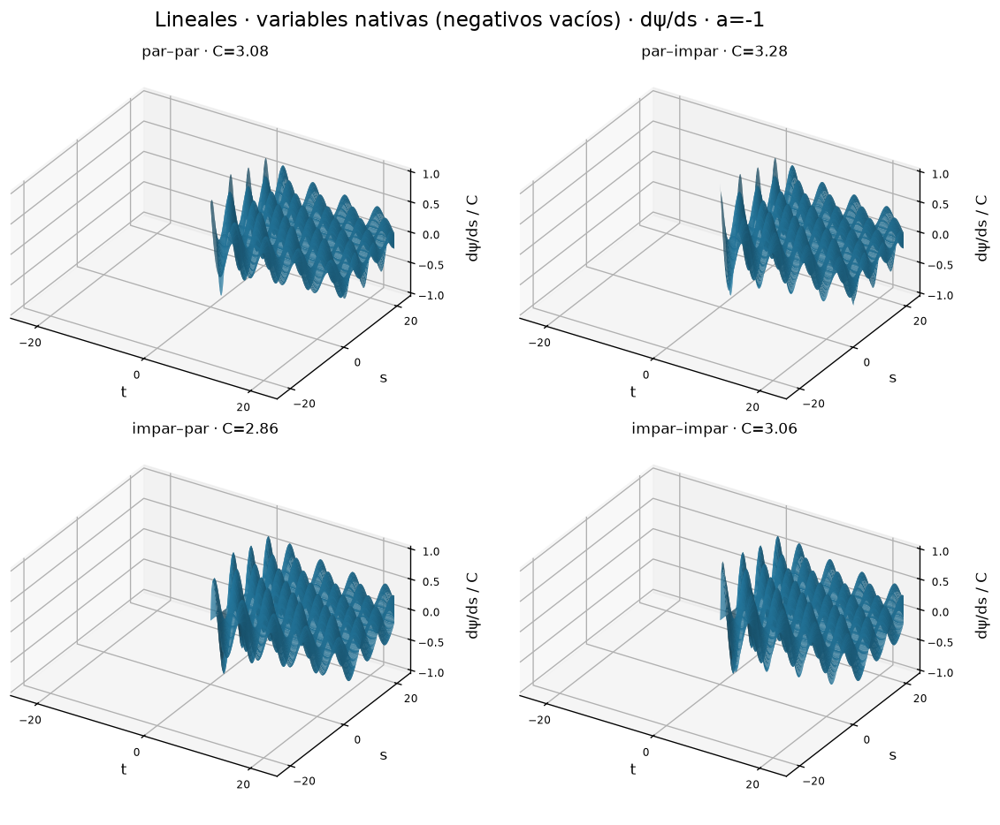

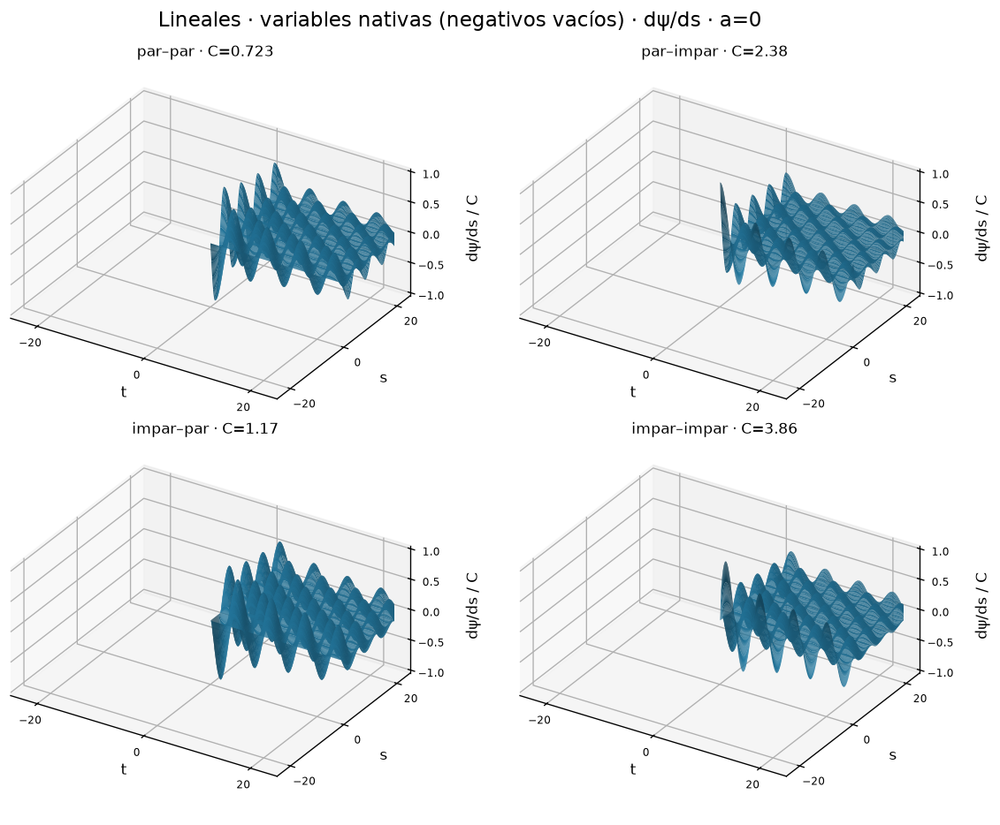

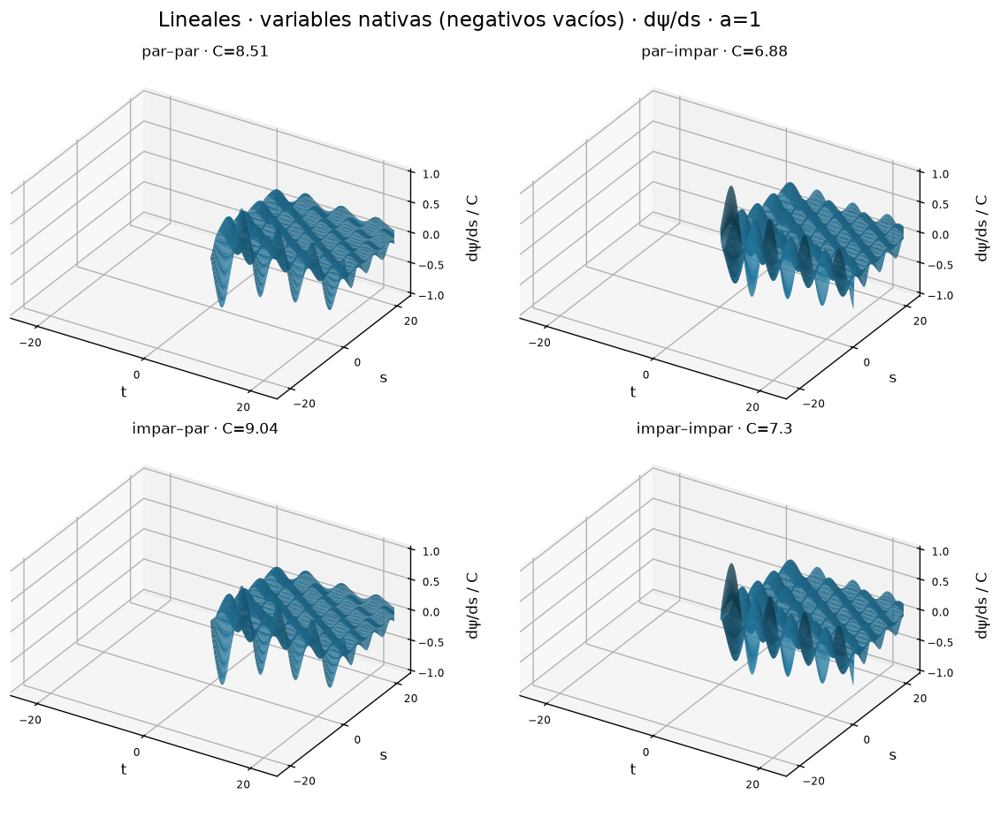

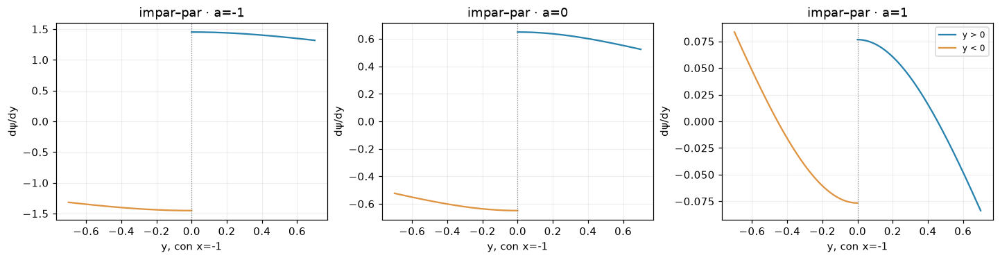

In [6]:
for system in ('quadratic','linear'):
    for quantity in ('d1','d2'):
        for a in A_VALUES:
            atlas(system,a,quantity)

# Perfil del salto de derivada que puede ser difícil de ver en una superficie general.
fig,axes=plt.subplots(1,3,figsize=(13,3.3),layout='constrained')
y0=np.linspace(1e-5,.7,350)
for ax,a in zip(axes,A_VALUES):
    for side,color in ((1,'#2783ad'),(-1,'#df9441')):
        dy=wc.field_quadratic(-np.ones_like(y0),side*y0,a,'odd','even',quantity='d2')
        ax.plot(side*y0,dy,color=color,label=f'y {">" if side==1 else "<"} 0')
    ax.set(title=f'impar–par · a={a:g}',xlabel='y, con x=-1',ylabel='dψ/dy')
    ax.axvline(0,color='.5',ls=':',lw=.8);ax.grid(alpha=.2)
axes[-1].legend(fontsize=8)
fig.savefig(OUT/'derivada_corte_impar_par.png',dpi=220)
plt.show();plt.close(fig)

## 6. Explorador 3D: campo y derivadas

Seleccionar el sistema, $a$ y el campo o derivada. Los ejes horizontales siempre abarcan
$[-25,25]$. La altura se normaliza por panel. En cuadráticas los ejes son $x,y$;
en lineales son $t,s$ y los negativos quedan vacíos. El selector no reparametriza los datos.
Los cuatro paneles tienen menos separación; el HTML es autónomo y permite rotación y zoom.

In [7]:
figi=make_subplots(rows=2,cols=2,specs=[[{'type':'surface'}]*2]*2,
    subplot_titles=[name for _,_,name in PARITIES],horizontal_spacing=.015,vertical_spacing=.035)
states=[]
for system in ('quadratic','linear'):
    for quantity in ('field','d1','d2'):
        for a in A_VALUES:
            xs=[];ys=[];zs=[];visible=[];names=[]
            for name,scale,group in wc.normalized_pieces(system,a,quantity,SPAN,101):
                for slot in range(2):
                    if slot<len(group):
                        x,y,z,side=group[slot]
                        xs.append(x[0].tolist());ys.append(y[:,0].tolist())
                        zs.append(np.where(np.isfinite(z),z,np.nan).tolist());visible.append(True)
                    else:
                        xs.append([0]);ys.append([0]);zs.append([[None]]);visible.append(False)
                    names.append(f'{name}; C={scale:.5g}')
            xl,yl,zl=wc.axis_labels(system,quantity)
            label=f'{"cuadráticas (x,y)" if system=="quadratic" else "lineales nativas (t,s)"} · {zl} · a={a:g}'
            states.append((label,xs,ys,zs,visible,names,xl,yl,zl))
for i in range(8):
    label,xs,ys,zs,visible,names,*_=states[0]
    color='#2783ad' if i%2==0 else '#df9441'
    figi.add_trace(go.Surface(x=xs[i],y=ys[i],z=zs[i],visible=visible[i],name=names[i],
        colorscale=[[0,color],[1,color]],showscale=False,connectgaps=False,
        hovertemplate='u=%{x:.3f}<br>v=%{y:.3f}<br>altura=%{z:.6f}<extra>%{fullData.name}</extra>'),
        row=i//4+1,col=(i//2)%2+1)
buttons=[]
for label,xs,ys,zs,visible,names,xl,yl,zl in states:
    layout={'title.text':'Weber 3D · '+label+' · escala por panel'}
    for k in range(4):
        scene='scene'+(str(k+1) if k else '')
        layout[scene+'.xaxis.title.text']=xl;layout[scene+'.yaxis.title.text']=yl
        layout[scene+'.zaxis.title.text']=zl+' / C'
        layout[scene+'.xaxis.range']=[-25,25];layout[scene+'.yaxis.range']=[-25,25]
    buttons.append(dict(label=label,method='update',args=[dict(x=xs,y=ys,z=zs,visible=visible,name=names),layout]))
figi.update_layout(title='Weber 3D · cuadráticas · campo · a=-1 · escala por panel',
    height=830,width=1200,margin=dict(t=100,b=5,l=5,r=5),
    updatemenus=[dict(buttons=buttons,x=0,y=1.10,xanchor='left',yanchor='top')])
figi.update_scenes(xaxis_title='x',yaxis_title='y',zaxis_title='campo / C',
    xaxis_range=[-25,25],yaxis_range=[-25,25],zaxis_range=[-1.05,1.05],
    aspectmode='manual',aspectratio=dict(x=1.25,y=1,z=.65),
    camera=dict(projection=dict(type='orthographic'),eye=dict(x=1.5,y=-1.7,z=1.25)))
figi.write_html(str(OUT/'Weber_3D_interactivo.html'),include_plotlyjs=True,
    config={'responsive':True,'displaylogo':False,'toImageButtonOptions':{'format':'png','width':3840,'height':2160,'scale':1}})
if MOSTRAR_INTERACTIVO:
    display(HTML(figi.to_html(include_plotlyjs=True,full_html=False,config={'responsive':True,'displaylogo':False})))

## 7. Animaciones 4K / 60 fps

Se renderizan dos vídeos de ocho segundos con $a$ variando de $-4$ a $4$, sin interpolar
fotogramas ni aumentar artificialmente una exportación pequeña. Cada fotograma evalúa
las cuatro soluciones. La salida es 3840 × 2160 y usa una escala de altura por panel
y fotograma; no comparar amplitudes absolutas entre instantes sin deshacer esa escala.
La función de render está completa y los vídeos ya renderizados se reproducen abajo.

In [8]:
ANIMATION_DIRECTORY=Path.cwd()/'Weber_Animaciones'
RENDERIZAR_ANIMACIONES=False  # True para recalcular ambos vídeos 4K/60fps.
videos=[]
for system in ('quadratic','linear'):
    path=ANIMATION_DIRECTORY/f'Weber_{system}_3D_4K_60fps.mp4'
    if RENDERIZAR_ANIMACIONES:
        wc.animate_weber_3d(system=system,a_initial=-4,a_final=4,duration_seconds=8,
            fps=60,spatial_domain=(-25,25),pts_phys=121,output=path,width=3840,height=2160)
    if path.exists():
        videos.append(str(path))
        display(Video(url='Weber_Animaciones/'+path.name,embed=False,width=900))
    else:
        print('Disponible al renderizar:',path)